# 04 — Anomaly Detection

Picks up from notebook 02 (uses the plain Random Forest). Two approaches are applied and cross-checked:

1. **Residual-based (main method):** flag hours where the forecast error is unusually large *compared with what is normal on the validation period*.
2. **Isolation Forest (cross-check):** an unsupervised detector that does not use the forecast error at all.

Two design choices that matter:
- **The threshold is calibrated on the validation set, not on the test set.** If the threshold is computed from the test residuals and then applied to the same test set, a fixed fraction of points is always flagged by construction — which proves nothing.
- **Relative residual.** A 1 kW error is huge when usage is 0.3 kW and normal when usage is 4 kW. So we use `(actual - predicted) / (predicted + eps)`, then a robust z-score (median and MAD, which are not distorted by the spikes themselves).

## 4.1 Load model and data

In [2]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

IN_DIR = "/kaggle/input/notebooks/azizullahasad/02-feature-enginering-and-baseline-model" 
WORK_DIR = "/kaggle/working/"   

bundle = joblib.load(f"{IN_DIR}/rf_plain_1h.pkl")
rf, features = bundle["model"], bundle["features"]

train = pd.read_csv(f"{IN_DIR}/house38_train.csv", index_col=0, parse_dates=True)
val = pd.read_csv(f"{IN_DIR}/house38_val.csv", index_col=0, parse_dates=True)
test = pd.read_csv(f"{IN_DIR}/house38_test.csv", index_col=0, parse_dates=True)
print(len(train), len(val), len(test))

5756 823 1645


## 4.2 Calibrate on validation, score the test period

1. Predict the validation period and compute relative residuals. `median` and `sigma` describe what a *normal* error looks like.
2. Predict the test period, compute relative residuals and convert them to a z-score with the validation `median` and `sigma`.
3. Flag `|z| > K`. A positive z is a **spike** (usage higher than expected), a negative z is a **drop**.

In [3]:
# 1) calibrate on validation
pred_val = rf.predict(val[features])
eps = 0.1 * val["y"].mean()                                   # keeps the ratio stable when predictions are tiny
rel_val = (val["y"].values - pred_val) / (pred_val + eps)
median = np.median(rel_val)
sigma = 1.4826 * np.median(np.abs(rel_val - median))          # robust spread (MAD)
print("validation median:", round(median, 4), "| sigma:", round(sigma, 4))

# 2) score test
pred_test = rf.predict(test[features])
rel_test = (test["y"].values - pred_test) / (pred_test + eps)
z = (rel_test - median) / sigma

# 3) flag
K = 5
results = pd.DataFrame({"actual": test["y"], "predicted": pred_test, "z": z}, index=test.index)
results["anomaly"] = results["z"].abs() > K
results["type"] = np.where(results["z"] > 0, "spike", "drop")

print(f"\nTest hours: {len(results)} | anomalies at K={K}: {int(results['anomaly'].sum())} "
      f"({100 * results['anomaly'].mean():.2f} %)")
results[results["anomaly"]].round(3)

validation median: 0.1227 | sigma: 0.4095

Test hours: 1645 | anomalies at K=5: 3 (0.18 %)


,actual,predicted,z,anomaly,type
datetime,,,,,
2024-06-19 02:00:00,5.740,1.532,5.762,True,spike
2024-06-19 03:00:00,5.816,1.717,5.021,True,spike
2024-06-19 04:00:00,5.788,1.673,5.173,True,spike


## 4.3 Sensitivity: how many alerts at different thresholds?

`K` is the sensitivity knob. A lower `K` raises more alerts (more false alarms), a higher `K` only the most extreme events. A dashboard can expose this as a slider.

In [4]:
rows = []
for k in [3.5, 4, 5, 6, 8]:
    n_flag = int((results["z"].abs() > k).sum())
    rows.append({"K": k, "anomalies": n_flag, "rate (%)": round(100 * n_flag / len(results), 2)})
pd.DataFrame(rows)

,K,anomalies,rate (%)
0,3.5,5,0.30
1,4.0,3,0.18
2,5.0,3,0.18
3,6.0,0,0.00
4,8.0,0,0.00


## 4.4 Visual checks

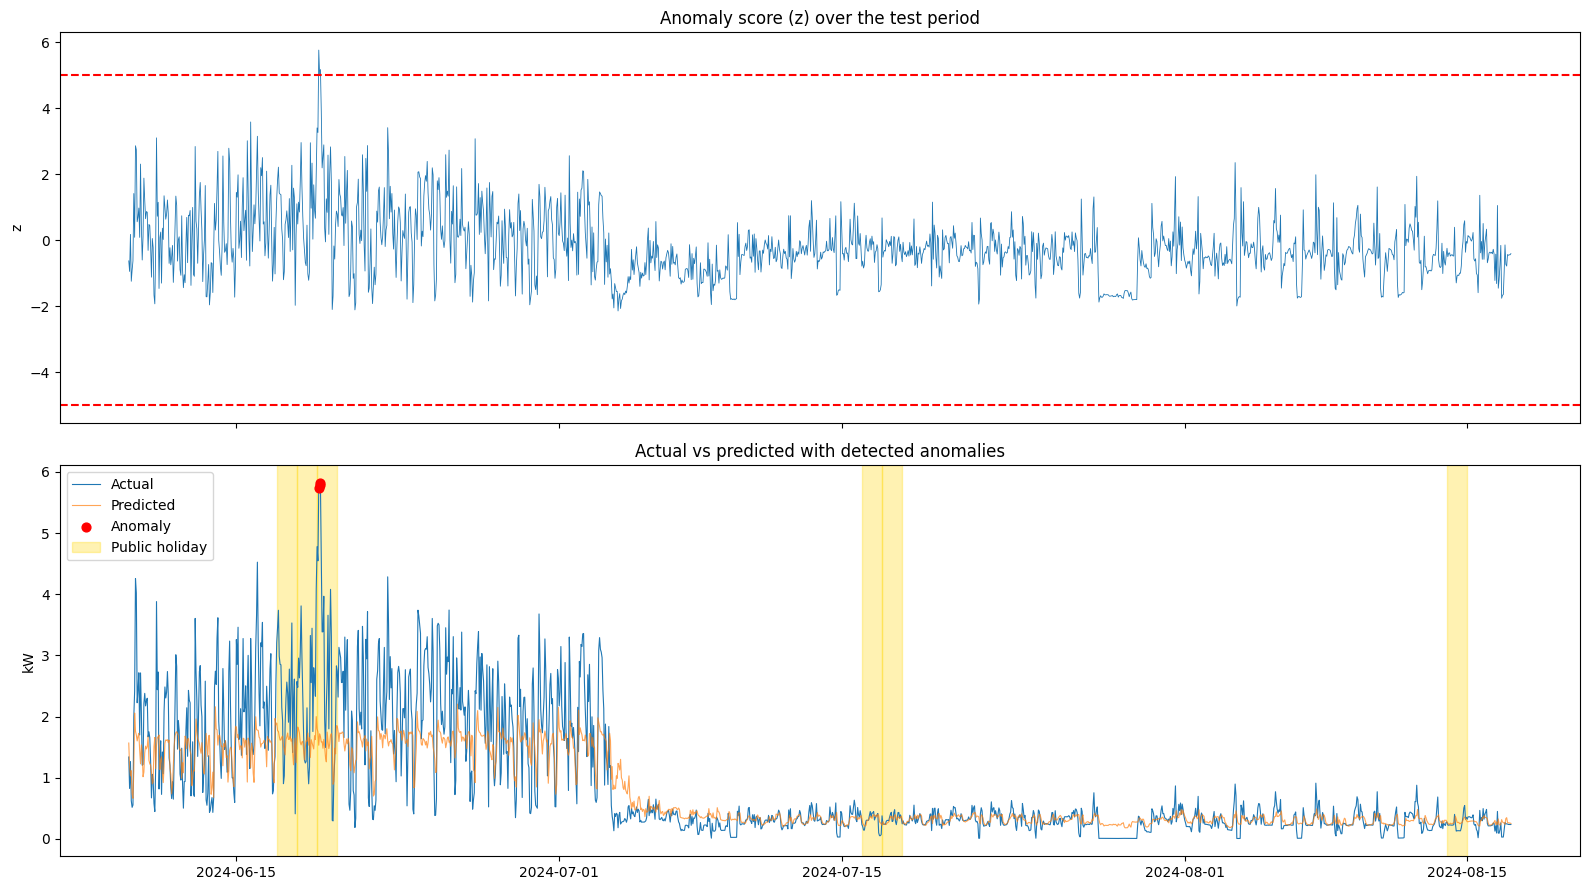

In [5]:
# public holidays that fall in the test window (verify the dates against a calendar)
HOLIDAYS = pd.to_datetime(["2024-06-17", "2024-06-18", "2024-06-19",   # Eid ul Adha
                           "2024-07-16", "2024-07-17",                 # Ashura
                           "2024-08-14"])                              # Independence Day

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

axes[0].plot(results.index, results["z"], linewidth=0.6)
axes[0].axhline(K, color="red", linestyle="--")
axes[0].axhline(-K, color="red", linestyle="--")
axes[0].set_title("Anomaly score (z) over the test period")
axes[0].set_ylabel("z")

axes[1].plot(results.index, results["actual"], label="Actual", linewidth=0.8)
axes[1].plot(results.index, results["predicted"], label="Predicted", linewidth=0.8, alpha=0.7)
flagged = results[results["anomaly"]]
axes[1].scatter(flagged.index, flagged["actual"], color="red", s=40, zorder=5, label="Anomaly")
for i, day in enumerate(HOLIDAYS):
    if results.index.min() <= day <= results.index.max():
        axes[1].axvspan(day, day + pd.Timedelta(days=1), color="gold", alpha=0.3,
                        label="Public holiday" if i == 0 else None)
axes[1].set_title("Actual vs predicted with detected anomalies")
axes[1].set_ylabel("kW")
axes[1].legend()

plt.tight_layout()
plt.show()

**Sustained level shifts.** The detector is built for *point* anomalies. If usage drops to a new level and stays there, the lag-based model adapts within a few days and the alarm never fires. A rolling mean of the error makes such a drift visible:

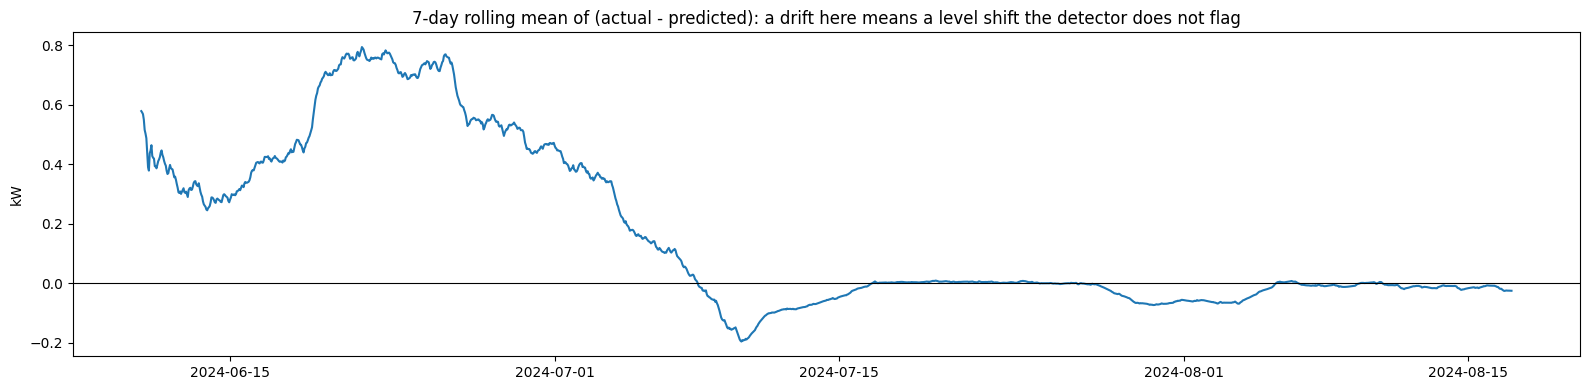

In [6]:
drift = (results["actual"] - results["predicted"]).rolling(24 * 7, min_periods=24).mean()

plt.figure(figsize=(16, 4))
plt.plot(drift.index, drift.values)
plt.axhline(0, color="k", linewidth=0.8)
plt.title("7-day rolling mean of (actual - predicted): a drift here means a level shift the detector does not flag")
plt.ylabel("kW")
plt.tight_layout()
plt.show()

## 4.5 Cross-check with Isolation Forest

Isolation Forest looks at the feature space directly. It is fitted on the **training** period only and applied to the test period. Note that `contamination=0.02` forces it to flag about 2% of points by design, so what is informative here is **how much it overlaps** with the residual method, not its own rate.

In [7]:
iso_features = features + ["y"]
iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=42)
iso.fit(train[iso_features])

iso_flag = iso.predict(test[iso_features]) == -1
res_flag = results["anomaly"].values

print("Isolation Forest flagged :", int(iso_flag.sum()), f"({100 * iso_flag.mean():.2f} %)")
print("Residual method flagged  :", int(res_flag.sum()), f"({100 * res_flag.mean():.2f} %)")
print("Flagged by BOTH          :", int((iso_flag & res_flag).sum()))

Isolation Forest flagged : 502 (30.52 %)
Residual method flagged  : 3 (0.18 %)
Flagged by BOTH          : 3


In [8]:
n_anom = int(results["anomaly"].sum())
print(f"At K={K}: {n_anom} anomalies in {len(results)} test hours ({100 * n_anom / len(results):.2f} %)")
if n_anom > 0:
    worst = results.loc[results["z"].abs().idxmax()]
    print("Strongest anomaly:", results["z"].abs().idxmax(), "| type:", worst["type"],
          "| actual:", round(worst["actual"], 2), "kW | predicted:", round(worst["predicted"], 2), "kW")
    on_holiday = results[results["anomaly"]].index.normalize().isin(HOLIDAYS).sum()
    print("Anomalies that fall on a public holiday:", int(on_holiday))

At K=5: 3 anomalies in 1645 test hours (0.18 %)
Strongest anomaly: 2024-06-19 02:00:00 | type: spike | actual: 5.74 kW | predicted: 1.53 kW
Anomalies that fall on a public holiday: 3


### Key findings

- Because the threshold is calibrated on validation, the number of alerts is a **real result**, not a fixed percentage. In our run on the real House 38 data only a handful of extreme hours were flagged at `K = 5` (see your output above).
- Anomalies often sit on **unusual days** (e.g. public holidays such as Eid), which suggests a calendar feature would reduce false alarms. With only a few holiday days in the test window this can be noted but not proven.
- **Limitation:** sustained level shifts (a house whose load drops by 80% for weeks) are not flagged; change-point detection (e.g. CUSUM) would be needed.
- Isolation Forest agrees only partly with the residual method — they look for different things (unusual feature combinations vs. unexpected forecast errors).

**Next notebook:** `05_multi_city_comparative_analysis.ipynb`

In [9]:
results.to_csv(f"{WORK_DIR}/house38_anomaly_results.csv")
print("Saved house38_anomaly_results.csv")

Saved house38_anomaly_results.csv
